# Each channel against its own baseline, the sum of the corrected channels, and the two branches of A against B (-82 V, DCRC1pB trigger)

*Draft prepared with Claude Code for A. Villano, 2026-11-03.*

`am-lines-baseline-82v.ipynb` corrected the *sums* of channels by the mean of their baselines. This notebook corrects **each channel by its own `baseline_mean`** (the 59.5 keV band of that channel followed in 24 bins of its baseline, a cubic of the logarithm fitted and divided out), sums the corrected channels, and fits all the lines of the spectrum at once. Then it looks at corrected A against corrected B, where a faint **lower branch** and a thin **upper tail** of B/A are found, shows what their pulses are (a high baseline, and a late pulse in the fit region), and cuts the high baselines.

Events, cuts and patch are those of the other notebook (`r76-82V-window-integral-tail.dataset.toml`: the line fitted to the tail, window samples 400 to 1500; the patch is 4.5 us around (10.4, 4.1) us). Nothing is calibrated; positions are in ADC counts x s. Run with the `darkmatter_cli_env` kernel. The movies of the pulses (`figures/*branch*events.gif`) were made with scripts, not here; the static pulses are drawn below.

In [1]:
import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pyarrow.compute as pc
import pyarrow.parquet as pq
from matplotlib import colors

from goldpan.dataset import Dataset

LETTERS = "ABCDEF"
_here = Path.cwd().resolve()
PROCESSING = next(p / "data_analysis" / "R76" / "processing" for p in [_here, *_here.parents] if (p / "data_analysis" / "R76" / "processing").is_dir())
OUT_CUTS = Path(Dataset.open(PROCESSING / "r76-82v-dcrc1pb.dataset.toml").spec.output)          # the cuts, as in positions-small-quiet-82v
OUT_WIN = Path(Dataset.open(PROCESSING / "r76-82V-window-integral-tail.dataset.toml").spec.output)   # the window integral and the heights
PRE = json.loads((OUT_CUTS / "_goldpan.json").read_text(encoding="utf-8"))["streams"]["NAI-S2"]["detector"]["segments"][0]["pretrigger_samples"]
CACHE = Path.home() / "goldsluice-output" / f"relcal-positions-small-82v-p{PRE}.npz"             # the cache of positions-small-quiet-82v
WCACHE = Path.home() / "goldsluice-output" / "relcal-window-integral-tail-82v.npz"               # this notebook's: the window integral and the row check
WCACHE_OLD = Path.home() / "goldsluice-output" / "relcal-window-integral-82v.npz"               # that of window-integral-small-quiet-82v (r76-82V-window-integral)

def field(tab, k, name):
    # one quantity of one channel: the channel is a struct column of the Parquet file
    return pc.struct_field(tab[f"Side2p{k}"].combine_chunks(), name).to_numpy(zero_copy_only=False)

def files(out):
    return sorted((out / "NAI-S2").glob("*_F[0-9][0-9][0-9][0-9].parquet"))

if CACHE.exists():
    z = np.load(CACHE)
    series, trigger, bstd, height, t = z["series"], z["trigger"], z["bstd"], z["height"], z["t"]
else:
    S_, T_, B_, H_, X_ = [], [], [], [], []
    for f in files(OUT_CUTS):
        tab = pq.read_table(f, columns=["series", "trigger_type"] + [f"Side2p{k}" for k in LETTERS])
        S_.append(np.asarray(tab["series"].to_pylist())); T_.append(np.asarray(tab["trigger_type"].to_pylist()))
        B_.append(np.column_stack([field(tab, k, "baseline_std") for k in LETTERS]))
        H_.append(np.column_stack([field(tab, k, "current_max") for k in LETTERS]))
        X_.append(np.column_stack([field(tab, k, "crossing_time_s") for k in LETTERS]) * 1e6)       # microseconds
    series, trigger, bstd, height, t = np.concatenate(S_), np.concatenate(T_), np.vstack(B_), np.vstack(H_), np.vstack(X_)
    np.savez(CACHE, series=series, trigger=trigger, bstd=bstd, height=height, t=t)

def keys(out, window=False):
    # series/dump/event of every row, and (window=True) the window integral of the six channels
    K, X = [], []
    for f in files(out):
        tab = pq.read_table(f, columns=["series", "dump", "event"] + ([f"Side2p{k}" for k in LETTERS] if window else []))
        K.append(np.array([f"{s}/{d}/{e}" for s, d, e in zip(tab["series"].to_pylist(), tab["dump"].to_pylist(), tab["event"].to_pylist())]))
        if window:
            X.append(np.column_stack([field(tab, k, "window_integral") for k in LETTERS]))
    return np.concatenate(K), (np.vstack(X) if window else None)

if WCACHE.exists():
    z = np.load(WCACHE)
    wint, same_rows = z["wint"], bool(z["same_rows"])
else:
    k_cuts, _ = keys(OUT_CUTS)
    k_win, wint = keys(OUT_WIN, window=True)
    same_rows = len(k_cuts) == len(k_win) and bool((k_cuts == k_win).all())
    np.savez(WCACHE, wint=wint, same_rows=same_rows)
assert same_rows and len(wint) == len(series), "the two datasets do not hold the same events in the same order"
real, rand = trigger == "Unknown", trigger == "Physics"
print(f"{len(series):,} events in {len(np.unique(series))} series, the same rows in both datasets: {real.sum():,} real triggers")

1,466,349 events in 8 series, the same rows in both datasets: 1,436,655 real triggers


In [2]:
SATH = np.array([1277, 1095, 589, 930, 680, 883.0])         # saturated height of each channel (saturation-over-time.ipynb)
FRAC = 0.05
BSTD_CUT = np.array([2 * np.median(bstd[rand, i]) for i in range(6)])
WINDOW = 60.0                                               # microseconds: the six times of one pulse lie within this of their median
OFFSET_X, OFFSET_Y = 0.5, 12.0                              # the re-centred plane of positions-small-quiet-82v
BLOB_X, BLOB_Y = 22.0, 2.0                                  # us, in that plane: the densest point of the small events
BLOB_R = 4.0        # us: the tight blob. The density of the small events is 53, 48, 46, 43 per us^2 in 1 us rings out to 4 us, and halves by about 7 us
BLOB_R_OUT = 10.0   # us: the old blob circle (the density falls to a quarter); the comparison set is outside it
EXCLUDE = {"07221113_1159"}
SIZE_CUT = False                                            # True: no channel above FRAC of its saturation (positions-small-quiet-82v)

keep = ~np.isin(series, list(EXCLUDE))
bstd_ok = (bstd < BSTD_CUT).all(axis=1)
small = (height < FRAC * SATH).all(axis=1)
size_ok = small if SIZE_CUT else np.ones(len(series), bool)
finite = np.isfinite(t).all(axis=1)
with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)
    one_pulse = (np.abs(t - np.nanmedian(t, axis=1, keepdims=True)) < WINDOW).all(axis=1)
xdel = t[:, 4] - 0.5 * (t[:, 2] + t[:, 3]) + OFFSET_X
ydel = 0.866 * (t[:, 3] - t[:, 2]) + OFFSET_Y
steps = [("real triggers", real & keep), ("+ bstd below the cut in all six channels", real & keep & bstd_ok),
         ("+ no channel above 5 % of its saturation" if SIZE_CUT else "  (no cut on the size)", real & keep & bstd_ok & size_ok),
         ("+ six 20 % times", real & keep & bstd_ok & size_ok & finite),
         ("+ one pulse (times within 60 us)", real & keep & bstd_ok & size_ok & finite & one_pulse)]
for name, m in steps:
    print(f"{name:<46}{m.sum():>11,}")
use = steps[-1][1]
r_blob = np.hypot(xdel - BLOB_X, ydel - BLOB_Y)
blob, rest = use & (r_blob < BLOB_R), use & (r_blob >= BLOB_R_OUT)
randoms = rand & keep
print(f"{'   in the blob':<46}{blob.sum():>11,}")
print(f"{'   between 4 and 10 us (in neither set)':<46}{(use & (r_blob >= BLOB_R) & (r_blob < BLOB_R_OUT)).sum():>11,}")
print(f"{'   outside the blob (beyond 10 us)':<46}{rest.sum():>11,}")
print(f"{'random triggers (for the zero)':<46}{randoms.sum():>11,}")

wsum = wint.sum(axis=1)                                     # all six channels, ADC counts x s
for name, m in (("selected", use), ("blob", blob), ("outside the blob", rest), ("random triggers", randoms)):
    p = np.percentile(wsum[m], [10, 50, 90])
    print(f"{name:>18}: summed window integral 10/50/90 %: " + "  ".join(f"{v:8.5f}" for v in p))

real triggers                                   1,292,982
+ bstd below the cut in all six channels        1,088,121
  (no cut on the size)                          1,088,121
+ six 20 % times                                1,053,964
+ one pulse (times within 60 us)                1,031,670
   in the blob                                      8,861
   between 4 and 10 us (in neither set)            95,769
   outside the blob (beyond 10 us)                927,040
random triggers (for the zero)                     25,511
          selected: summed window integral 10/50/90 %:  0.40083   2.42478   3.92647
              blob: summed window integral 10/50/90 %:  0.01787   0.04465   0.42861
  outside the blob: summed window integral 10/50/90 %:  0.64987   2.60056   3.96936
   random triggers: summed window integral 10/50/90 %: -0.19189  -0.00250   0.08418


In [3]:
# the patch: the events within PATCH_R of the centre of the excess of the 59.5 keV line (found in 2 us bins of the position plane,
# signal window minus sidebands, on the A + B integral); every series, the same place
PATCH_X, PATCH_Y, PATCH_R = 10.4, 4.1, 4.5
patch = use & (np.hypot(xdel - PATCH_X, ydel - PATCH_Y) < PATCH_R)
P = np.flatnonzero(patch)
print(f"{patch.sum():,} patch events ({patch.sum() / use.sum():.1%} of the selected), by series:")
for s_ in sorted(set(np.unique(series)) - EXCLUDE):
    print(f"  {s_}: {(patch & (series == s_)).sum():,}")

129,539 patch events (12.6% of the selected), by series:


  07221111_2153: 16,468
  07221112_0943: 34,969
  07221112_2249: 24,552
  07221114_2141: 9,638


  07221115_0845: 9,992
  07221115_2109: 17,549
  07221116_1003: 16,371


In [4]:
BCACHE = Path.home() / "goldsluice-output" / "relcal-baseline-mean-82v.npz"
if BCACHE.exists():
    bmean = np.load(BCACHE)["bmean"]
else:
    B_ = []
    for f in files(OUT_CUTS):
        tab = pq.read_table(f, columns=[f"Side2p{k}" for k in LETTERS])
        B_.append(np.column_stack([field(tab, k, "baseline_mean") for k in LETTERS]))
    bmean = np.vstack(B_)
    np.savez(BCACHE, bmean=bmean)
assert len(bmean) == len(series)
print("baseline_mean of the selected events (median, 1 to 99 %):")
for i, k in enumerate(LETTERS):
    print(f"  {k}: {np.median(bmean[use, i]):7.1f}  {np.percentile(bmean[use, i], 1):7.1f} .. {np.percentile(bmean[use, i], 99):7.1f}")

baseline_mean of the selected events (median, 1 to 99 %):
  A:  3176.4   3011.6 ..  3873.2


  B:  3193.1   3013.9 ..  3862.5
  C:  3157.1   2997.9 ..  3513.1


  D:  3183.1   3013.8 ..  3785.5
  E:  3176.7   3009.9 ..  3603.8


  F:  3162.7   2959.0 ..  3745.4


## The fit helpers

`gfit` (a Gaussian plus a straight line in a window), `track` (the position of the 59.5 keV peak in bins of the baseline) and `correct` (the fit of that position against the baseline and the division by it); the same as in the other notebook.

In [5]:
def gfit(v, lo, hi, nb=60):
    # Gaussian plus a straight line in [lo, hi]; returns (the chi2 gained by the Gaussian, its position, its width)
    e = np.linspace(lo, hi, nb + 1); c = 0.5 * (e[1:] + e[:-1]); h, _ = np.histogram(v, bins=e); w = 1 / np.sqrt(np.maximum(h, 1))
    mid = 0.5 * (lo + hi); M0 = np.column_stack([np.ones_like(c), c - mid])
    k0 = np.linalg.lstsq(M0 * w[:, None], h * w, rcond=None)[0]; chi0 = (((M0 @ k0 - h) * w) ** 2).sum()
    best = (1e18, None, None)
    for mu in np.linspace(lo + 0.2 * (hi - lo), hi - 0.2 * (hi - lo), 40):
        for sg in np.linspace(0.01 * (hi - lo), 0.25 * (hi - lo), 14):
            M = np.column_stack([np.exp(-0.5 * ((c - mu) / sg) ** 2), M0])
            k = np.linalg.lstsq(M * w[:, None], h * w, rcond=None)[0]
            if k[0] <= 0:
                continue
            chi = (((M @ k - h) * w) ** 2).sum()
            if chi < best[0]:
                best = (chi, mu, sg)
    return chi0 - best[0], best[1], best[2]

def track(x, v, init, nbins=24):
    # the position of the 59.5 keV peak of v in bins of the baseline x
    order = np.argsort(x); cut = np.linspace(0, len(x), nbins + 1).astype(int)
    xs, ps, prev = [], [], None
    for k in range(nbins):
        sel = order[cut[k]:cut[k + 1]]; vv = v[sel]
        hb = np.linspace(0.05, 3.5, 346); hs = np.convolve(np.histogram(vv, bins=hb)[0], np.ones(5) / 5, "same"); cb = hb[:-1] + 0.005
        lo, hi = init if prev is None else (prev * 0.72, prev * 1.04)
        pos = cb[np.argmax(np.where((cb > lo) & (cb < hi), hs, -1))]
        prev = gfit(vv, pos * 0.8, pos * 1.25)[1]
        xs.append(np.median(x[sel])); ps.append(prev)
    return np.array(xs), np.array(ps)

def correct(v, x, init):
    xs, ps = track(x, v, init)
    co = np.polyfit(xs, np.log(ps), 3)
    f = lambda xx: np.exp(np.polyval(co, xx))
    R = float(f(np.median(x)))
    return v * R / f(x), R, xs, ps, co

## 1. Each channel against its own baseline

The window integral of each channel for the patch events, against that channel's own `baseline_mean`. Every channel falls with its baseline; the line bands slope down together.

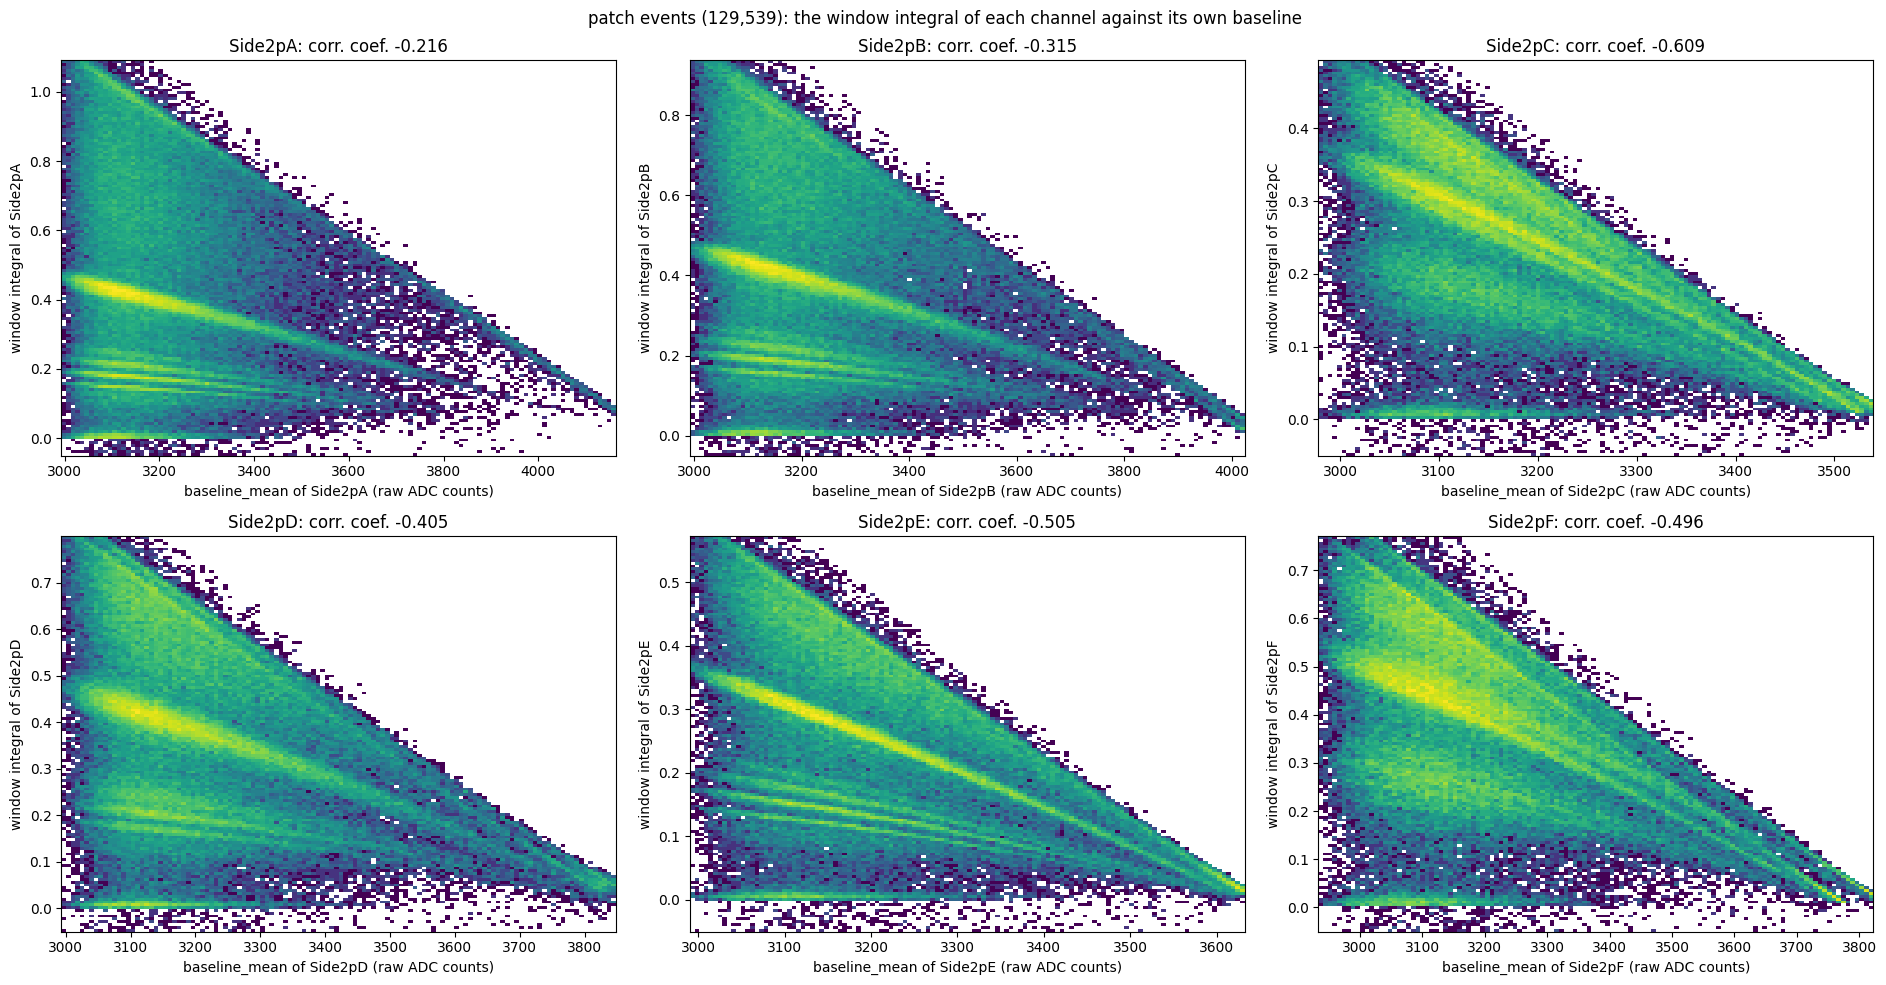

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(19, 10))
for i, ax in enumerate(axes.flat):
    x, y = bmean[P, i], wint[P, i]
    ax.hist2d(x, y, bins=[120, 140], range=[[np.percentile(x, .2), np.percentile(x, 99.8)], [-0.05, np.percentile(y, 99.7)]], norm=colors.LogNorm(), cmap="viridis")
    ax.set_title(f"Side2p{LETTERS[i]}: corr. coef. {np.corrcoef(x, y)[0, 1]:.3f}")
    ax.set_xlabel(f"baseline_mean of Side2p{LETTERS[i]} (raw ADC counts)"); ax.set_ylabel(f"window integral of Side2p{LETTERS[i]}")
fig.suptitle(f"patch events ({len(P):,}): the window integral of each channel against its own baseline")
fig.tight_layout()
plt.show()

## 2. Each channel corrected by its own baseline

The window of the search for the 59.5 keV band at the lowest baseline (`INIT`) is read off the plot above. The width and significance of the 59.5 keV peak are given before and after (Gaussian plus line; Delta chi^2 is the chi^2 gained by the Gaussian).

A: 59.5 keV at 0.404  sigma/mu before 0.068 after 0.033   dchi2 before   2399 after  13751


B: 59.5 keV at 0.397  sigma/mu before 0.079 after 0.033   dchi2 before   1337 after  12063


C: 59.5 keV at 0.271  sigma/mu before 0.078 after 0.045   dchi2 before    192 after   4292


D: 59.5 keV at 0.391  sigma/mu before 0.078 after 0.050   dchi2 before    634 after   8977


E: 59.5 keV at 0.272  sigma/mu before 0.079 after 0.033   dchi2 before    143 after  12706


F: 59.5 keV at 0.423  sigma/mu before 0.079 after 0.068   dchi2 before    348 after   4194


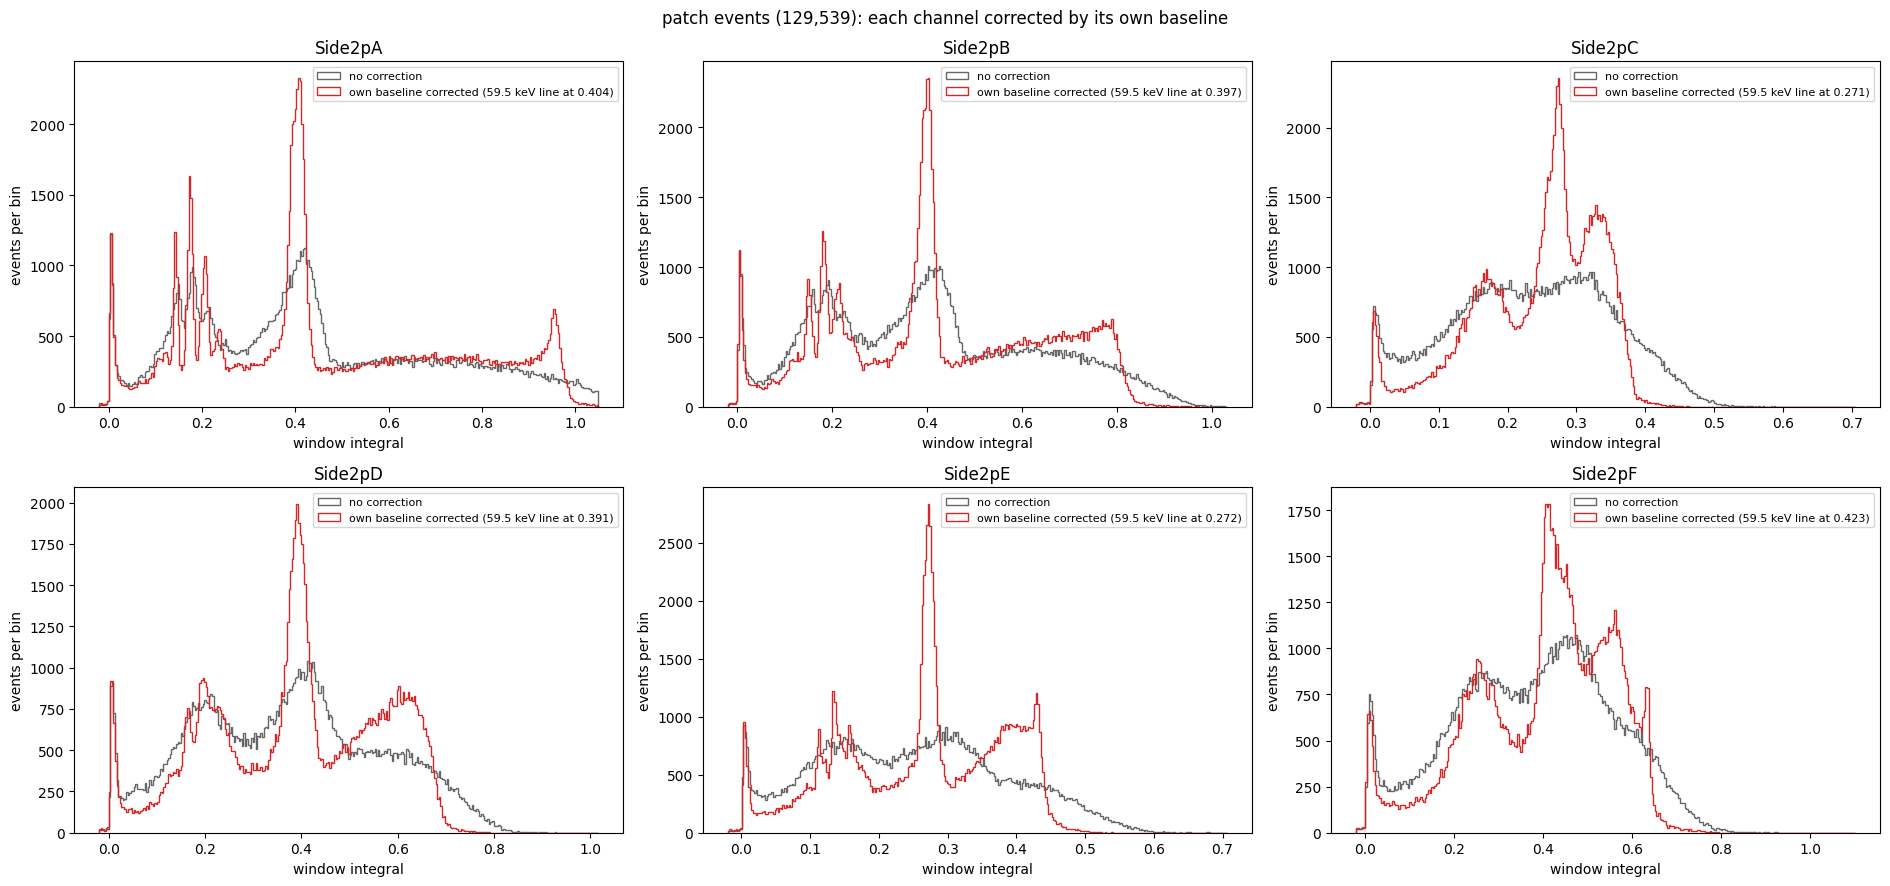

In [7]:
INIT = [(0.38, 0.52), (0.40, 0.54), (0.27, 0.36), (0.37, 0.50), (0.27, 0.37), (0.38, 0.55)]
CH = {}
fig, axes = plt.subplots(2, 3, figsize=(19, 9))
for i, ax in enumerate(axes.flat):
    v, x = wint[P, i], bmean[P, i]
    S_, R_, xs, ps, co = correct(v, x, INIT[i]); CH[i] = (S_, R_)
    up = gfit(S_, 0.85 * R_, 1.17 * R_, 80)
    hb = np.linspace(0.05, 3.5, 346); hs = np.convolve(np.histogram(v, bins=hb)[0], np.ones(5) / 5, "same"); cb = hb[:-1] + 0.005
    p0 = cb[np.argmax(np.where((cb > INIT[i][0] * 0.8) & (cb < INIT[i][1]), hs, -1))]; u0 = gfit(v, 0.85 * p0, 1.17 * p0, 80)
    print(f"{LETTERS[i]}: 59.5 keV at {R_:.3f}  sigma/mu before {u0[2] / u0[1]:.3f} after {up[2] / up[1]:.3f}   dchi2 before {u0[0]:6.0f} after {up[0]:6.0f}")
    bb = np.linspace(-0.02, 2.6 * R_, 320)
    ax.hist(v, bins=bb, histtype="step", color="0.4", label="no correction"); ax.hist(S_, bins=bb, histtype="step", color="C3", label=f"own baseline corrected (59.5 keV line at {R_:.3f})")
    ax.set_title(f"Side2p{LETTERS[i]}"); ax.set_xlabel("window integral"); ax.set_ylabel("events per bin"); ax.legend(fontsize=8)
fig.suptitle(f"patch events ({len(P):,}): each channel corrected by its own baseline")
fig.tight_layout()
plt.show()

## 3. The sum of the corrected channels and a fit of all the lines

The corrected channels are summed (A + B, C + D + E + F, A to F), and all the lines are fitted at once: eight Gaussians at 13.95 and 17.75 (Np L-alpha, L-beta), 26.34 and 59.54 keV (Am-241) with the energy fixed, three peaks near 22, 31 and 35 keV with the energy free, a width sigma = sqrt(a^2 + (c E)^2), a straight scale `position = k E + b`, and a smooth background (Chebyshev polynomial of degree 4); the amplitudes are linear and kept positive. The range starts above the blob of small pulses at zero (0.11 of the 59.5 keV position). The inner sum is not linear through zero (clipping), so its energies are approximate.

A + B: 0.01337/keV, offset +0.0040 (+0.30 keV), sigma = sqrt(0.000^2 + (0.0351 E)^2) keV; chi2/ndf 941/281
    Np La  13.95 keV  area       33  sigma/E 0.035
    Np Lb  17.75 keV  area      469  sigma/E 0.035
      ~22  21.65 keV  area     2851  sigma/E 0.035
       Am  26.34 keV  area     5137  sigma/E 0.035
      ~31  30.95 keV  area     3675  sigma/E 0.035
      ~36  35.16 keV  area     1267  sigma/E 0.035
       Am  59.54 keV  area    21822  sigma/E 0.035


C + D + E + F: 0.02185/keV, offset +0.0593 (+2.71 keV), sigma = sqrt(0.778^2 + (0.0265 E)^2) keV; chi2/ndf 1074/281
    Np La  13.95 keV  area       10  sigma/E 0.062
    Np Lb  17.75 keV  area       62  sigma/E 0.051
      ~22  21.28 keV  area      377  sigma/E 0.045
       Am  26.34 keV  area     2238  sigma/E 0.040
      ~31  31.40 keV  area     4311  sigma/E 0.036
      ~36  36.06 keV  area     2956  sigma/E 0.034
       Am  59.54 keV  area    21661  sigma/E 0.030


A to F: 0.03713/keV, offset -0.0496 (-1.34 keV), sigma = sqrt(0.350^2 + (0.0271 E)^2) keV; chi2/ndf 1504/282
    Np La  13.95 keV  area        0  sigma/E 0.037
    Np Lb  17.75 keV  area        7  sigma/E 0.034
      ~22  21.80 keV  area      402  sigma/E 0.032
       Am  26.34 keV  area     2432  sigma/E 0.030
      ~31  31.00 keV  area     4518  sigma/E 0.029
      ~36  35.41 keV  area     3109  sigma/E 0.029
       Am  59.54 keV  area    21846  sigma/E 0.028


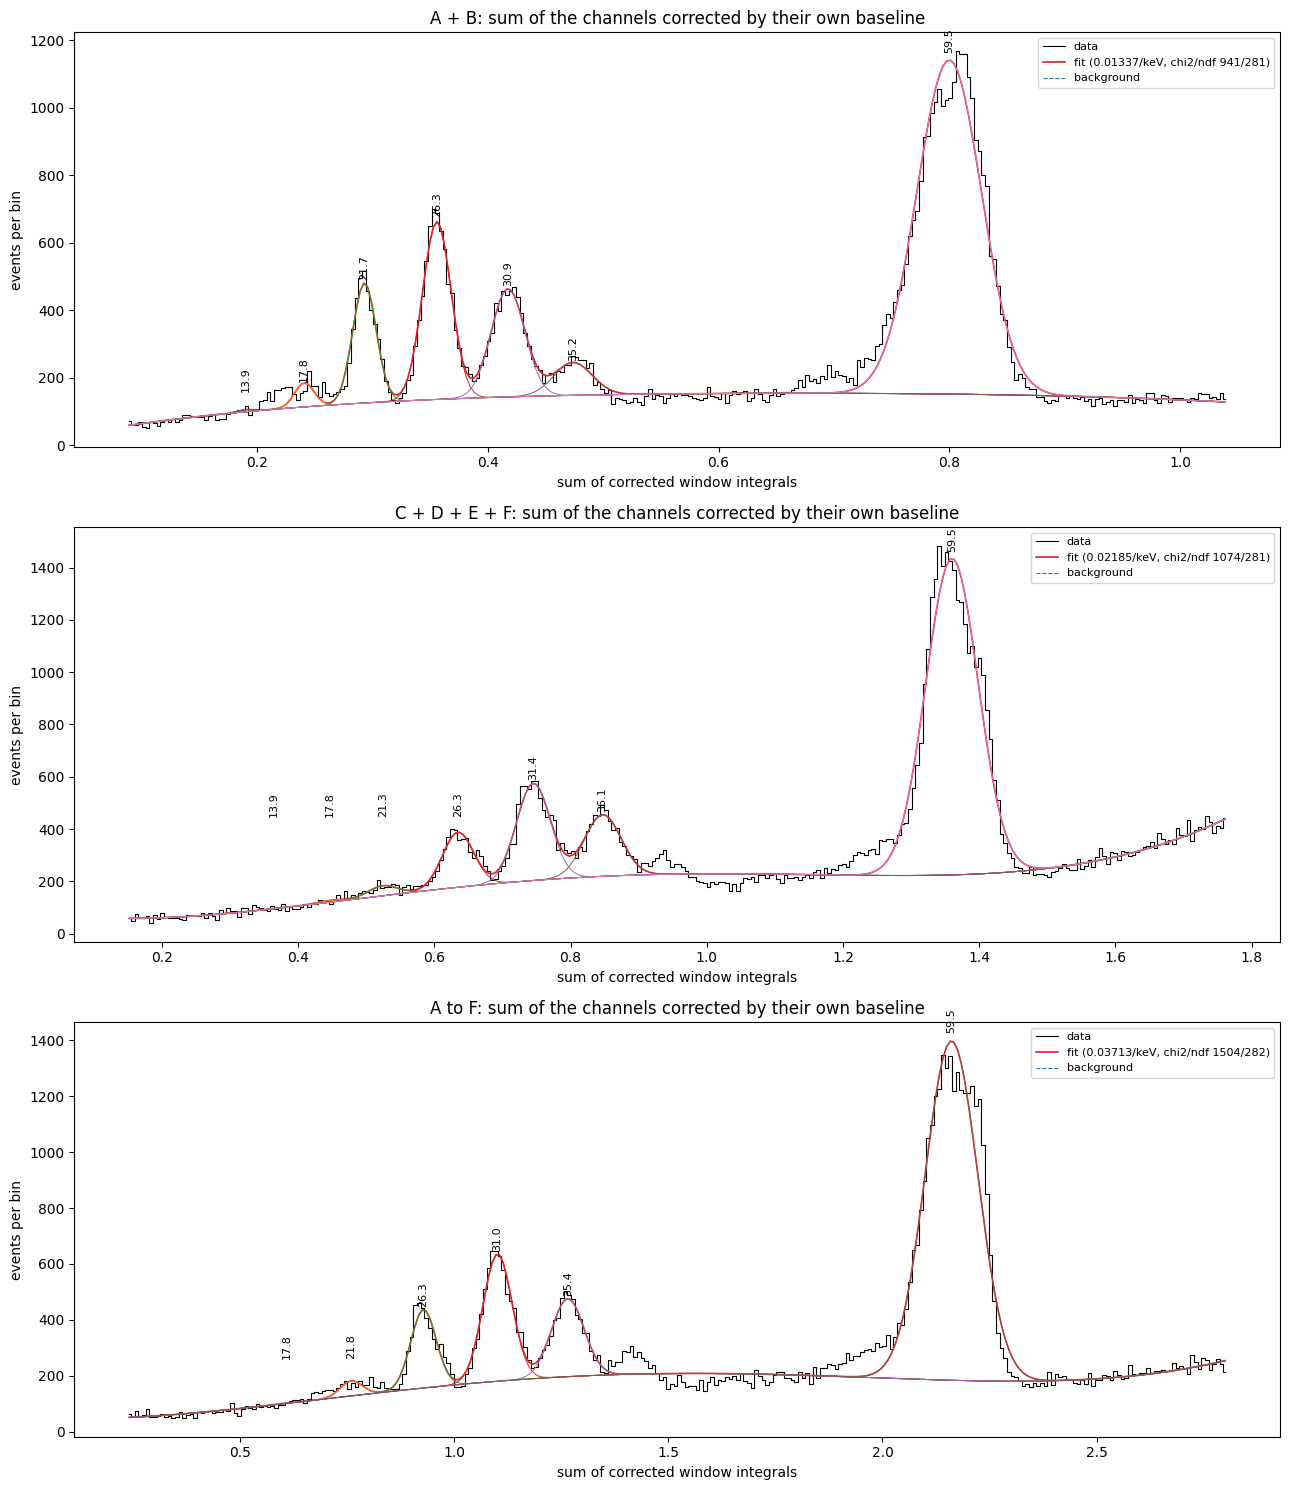

In [8]:
def nelder_mead(f, x0, step, it=1500):
    n = len(x0); sim = [np.array(x0, float)] + [np.array(x0, float) + np.eye(n)[i] * step[i] for i in range(n)]
    fv = [f(s_) for s_ in sim]
    for _ in range(it):
        o = np.argsort(fv); sim = [sim[i] for i in o]; fv = [fv[i] for i in o]
        c = np.mean(sim[:-1], axis=0); xr = c + (c - sim[-1]); fr = f(xr)
        if fr < fv[0]:
            xe = c + 2 * (c - sim[-1]); fe = f(xe)
            sim[-1], fv[-1] = (xe, fe) if fe < fr else (xr, fr)
        elif fr < fv[-2]:
            sim[-1], fv[-1] = xr, fr
        else:
            xc = c + 0.5 * (sim[-1] - c); fc = f(xc)
            if fc < fv[-1]:
                sim[-1], fv[-1] = xc, fc
            else:
                for i in range(1, n + 1):
                    sim[i] = sim[0] + 0.5 * (sim[i] - sim[0]); fv[i] = f(sim[i])
        if abs(fv[-1] - fv[0]) < 1e-6 and np.max(np.abs(sim[-1] - sim[0])) < 1e-7:
            break
    o = np.argmin(fv)
    return sim[o], fv[o]

NAMES = ["Np La", "Np Lb", "~22", "Am", "~31", "~36", "Am"]
def lines(p): return np.array([13.95, 17.75, p[4], 26.34, p[5], p[6], 59.54])     # keV: p[4:7] are the free ones
def design(c, p):
    k, b, a, cc = p[:4]; E = lines(p); pos = k * E + b; sg = np.sqrt(a ** 2 + (cc * E) ** 2) * k
    cols = [np.exp(-0.5 * ((c - m_) / g_) ** 2) for m_, g_ in zip(pos, sg)]
    x = (c - c.min()) / (c.max() - c.min()) * 2 - 1
    bg = [np.polynomial.chebyshev.chebval(x, np.eye(5)[j]) for j in range(5)]
    return np.column_stack(cols + bg), len(cols), sg
def solve(c, h, w, p):
    M, nl, sg = design(c, p); act = list(range(M.shape[1]))
    while True:
        k_ = np.linalg.lstsq(M[:, act] * w[:, None], h * w, rcond=None)[0]
        neg = [a_ for a_, v_ in zip(act, k_) if a_ < nl and v_ < 0]
        if not neg:
            break
        act = [a_ for a_ in act if a_ != neg[0]]
    co = np.zeros(M.shape[1]); co[act] = k_
    return M, co, nl, sg
def fit_lines(S, R59):
    e = np.linspace(0.11 * R59, 1.3 * R59, 301); c = 0.5 * (e[1:] + e[:-1]); h, _ = np.histogram(S, bins=e); w = 1 / np.sqrt(np.maximum(h, 1.0))
    def chi(p):
        if p[0] <= 0 or p[2] < 0 or p[3] < 0 or abs(p[2]) > 4 or p[3] > 0.2:
            return 1e12
        M, co, nl, sg = solve(c, h, w, p)
        return (((M @ co - h) * w) ** 2).sum()
    best = None
    for a0, b0 in ((0.3, 0.03), (0.1, 0.035), (0.6, 0.025)):
        p, f = nelder_mead(chi, [R59 / 59.54, 0.0, a0, b0, 21.9, 31.1, 35.6], [R59 / 59.54 * 0.01, R59 * 0.003, 0.1, 0.004, 0.4, 0.5, 0.5], it=2500)
        if best is None or f < best[1]:
            best = (p, f)
    p, f = best; M, co, nl, sg = solve(c, h, w, p)
    return c, h, M, co, nl, sg, p, f

SUMS = {"A + B": [0, 1], "C + D + E + F": [2, 3, 4, 5], "A to F": list(range(6))}
FITS = {}
fig, axes = plt.subplots(3, 1, figsize=(13, 15))
for ax, (name, idx_) in zip(axes, SUMS.items()):
    S = sum(CH[i][0] for i in idx_); R = sum(CH[i][1] for i in idx_)
    c, h, M, co, nl, sg, p, f = fit_lines(S, R); k, b = p[:2]; E = lines(p); FITS[name] = (p, f)
    ndf = len(h) - (7 + int((co[:nl] > 0).sum()) + 5)
    print(f"{name}: {k:.5f}/keV, offset {b:+.4f} ({b / k:+.2f} keV), sigma = sqrt({p[2]:.3f}^2 + ({p[3]:.4f} E)^2) keV; chi2/ndf {f:.0f}/{ndf}")
    dx = c[1] - c[0]; bgc = M[:, nl:] @ co[nl:]
    ax.step(c, h, where="mid", color="k", lw=0.8, label="data"); ax.plot(c, M @ co, "C3", lw=1.2, label=f"fit ({k:.5f}/keV, chi2/ndf {f:.0f}/{ndf})"); ax.plot(c, bgc, "C0--", lw=0.8, label="background")
    for j in range(nl):
        print(f"   {NAMES[j]:>6} {E[j]:6.2f} keV  area {co[j] * np.sqrt(2 * np.pi) * sg[j] / dx:8.0f}  sigma/E {sg[j] / k / E[j]:.3f}")
        if co[j] > 0:
            ax.plot(c, M[:, j] * co[j] + bgc, lw=0.7); ax.text(k * E[j] + b, (M[:, j] * co[j] + bgc).max() * 1.02, f"{E[j]:.1f}", ha="center", fontsize=8, rotation=90, va="bottom")
    ax.set_title(f"{name}: sum of the channels corrected by their own baseline"); ax.set_xlabel("sum of corrected window integrals"); ax.set_ylabel("events per bin"); ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

## 4. A against B, corrected; B/A against A

Corrected A against corrected B lie on one narrow diagonal; the lines are spots on it. B/A against A shows the lines as pairs of stripes on a band that slopes from 1.07 to 0.93, and, well below it, a faint **lower branch** (B/A about 0.35 to 0.55); above the band there is a thin tail (B/A above 1.12).

correlation of corrected A and B: 0.989; B/A (A > 0.08): median 0.964, 5 to 95 %: 0.811 to 1.062


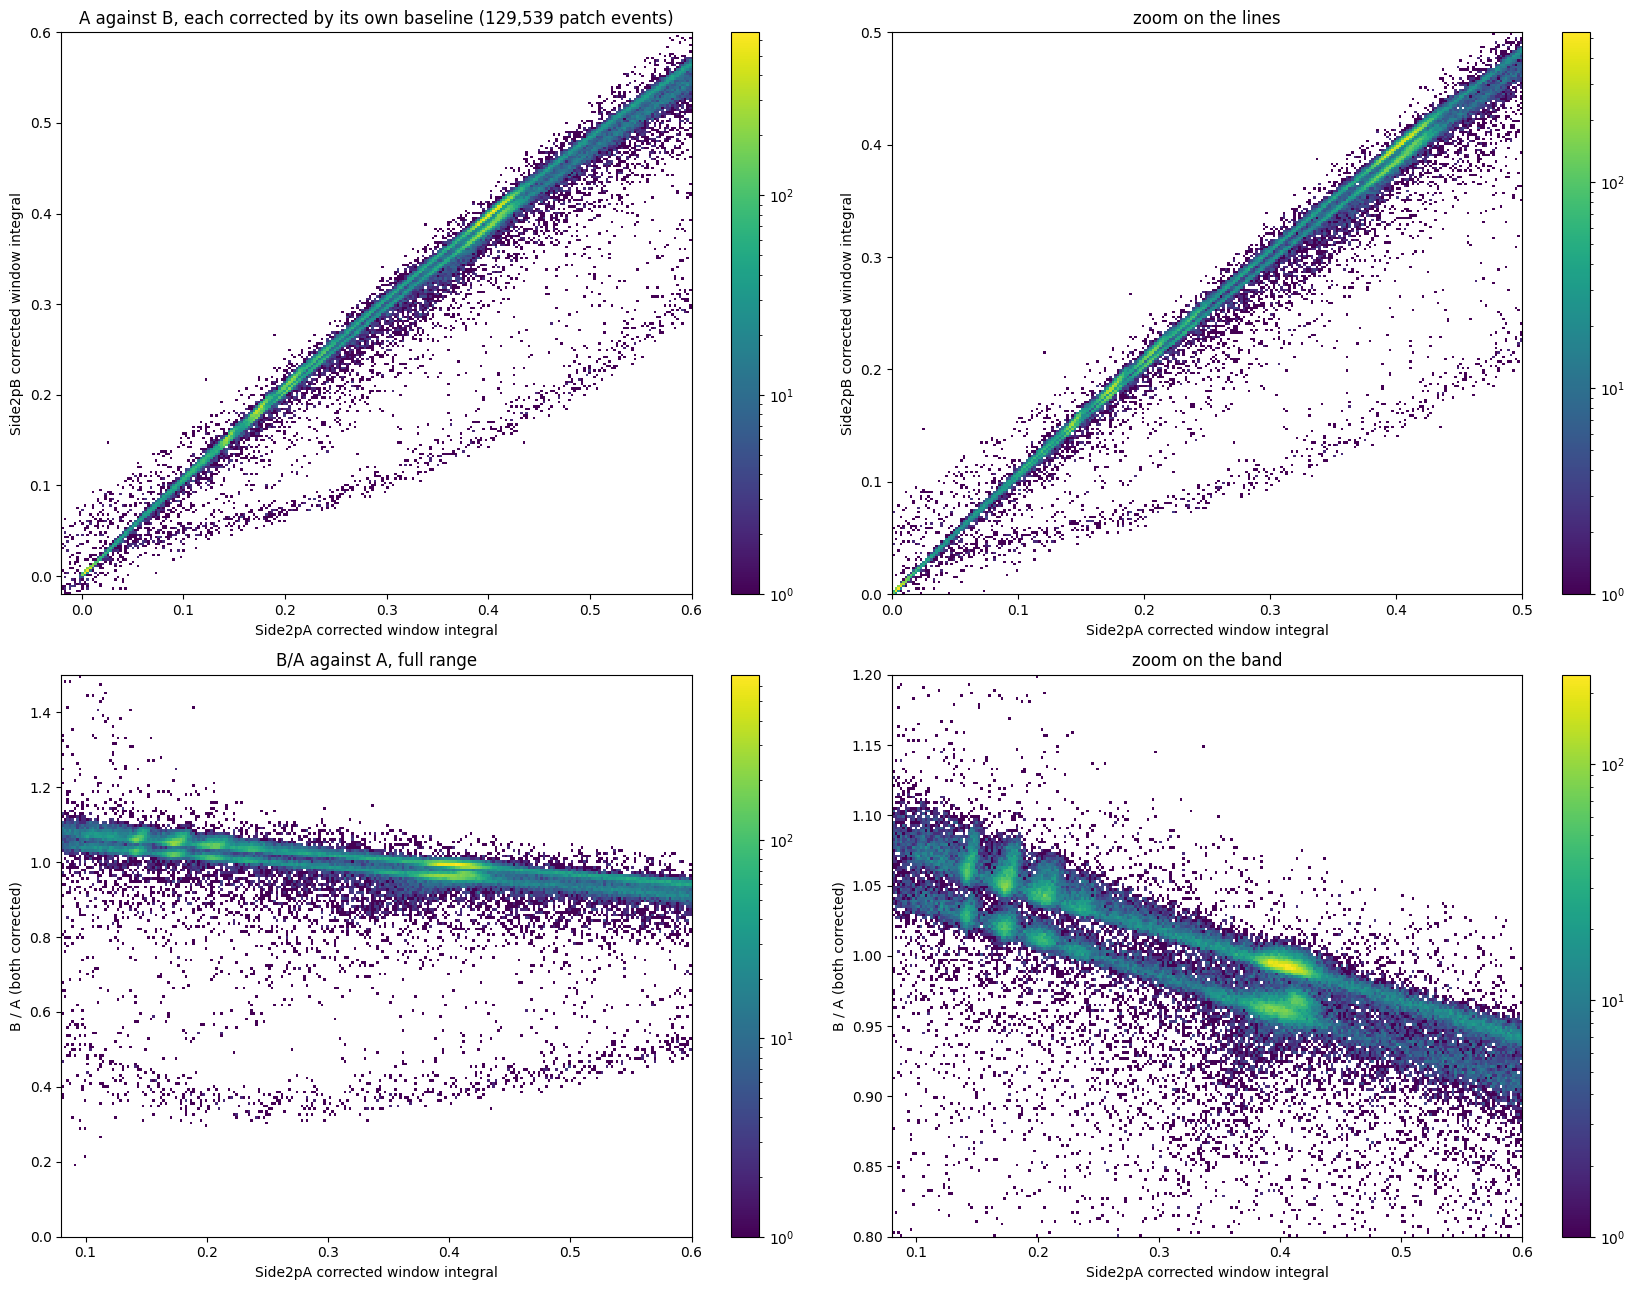

In [9]:
A_c, RA = CH[0]; B_c, RB = CH[1]
okc = A_c > 0.08; ratio = np.where(okc, B_c / np.maximum(A_c, 1e-9), np.nan)
print(f"correlation of corrected A and B: {np.corrcoef(A_c, B_c)[0, 1]:.3f}; B/A (A > 0.08): median {np.nanmedian(ratio):.3f}, 5 to 95 %: {np.nanpercentile(ratio, 5):.3f} to {np.nanpercentile(ratio, 95):.3f}")
fig, axes = plt.subplots(2, 2, figsize=(17, 13))
for ax, rg in zip(axes[0], ((-0.02, 0.6), (0.0, 0.5))):
    h = ax.hist2d(A_c, B_c, bins=[250, 250], range=[rg, rg], norm=colors.LogNorm(), cmap="viridis", cmin=1)
    ax.set_xlabel("Side2pA corrected window integral"); ax.set_ylabel("Side2pB corrected window integral"); plt.colorbar(h[3], ax=ax)
axes[0, 0].set_title(f"A against B, each corrected by its own baseline ({len(A_c):,} patch events)"); axes[0, 1].set_title("zoom on the lines")
for ax, rg in zip(axes[1], ((0, 1.5), (0.8, 1.2))):
    h = ax.hist2d(A_c[okc], ratio[okc], bins=[250, 200], range=[(0.08, 0.6), rg], norm=colors.LogNorm(), cmap="viridis", cmin=1)
    ax.set_xlabel("Side2pA corrected window integral"); ax.set_ylabel("B / A (both corrected)"); plt.colorbar(h[3], ax=ax)
axes[1, 0].set_title("B/A against A, full range"); axes[1, 1].set_title("zoom on the band")
fig.tight_layout()
plt.show()

## 5. The two branches and their baselines

Lower branch: corrected B/A below 0.6; upper tail: above 1.12 (both with corrected A above 0.1). The baselines of A of the events of each, against the main band.

corrected B/A < 0.6: 1,010 events; B/A > 1.12: 153; of 120,110 with A > 0.1
  lower branch  baseline of A: median   4036   10 to 90 %:   3910 ..   4182
  main band     baseline of A: median   3167   10 to 90 %:   3060 ..   3390
  upper tail    baseline of A: median   3199   10 to 90 %:   3068 ..   3461


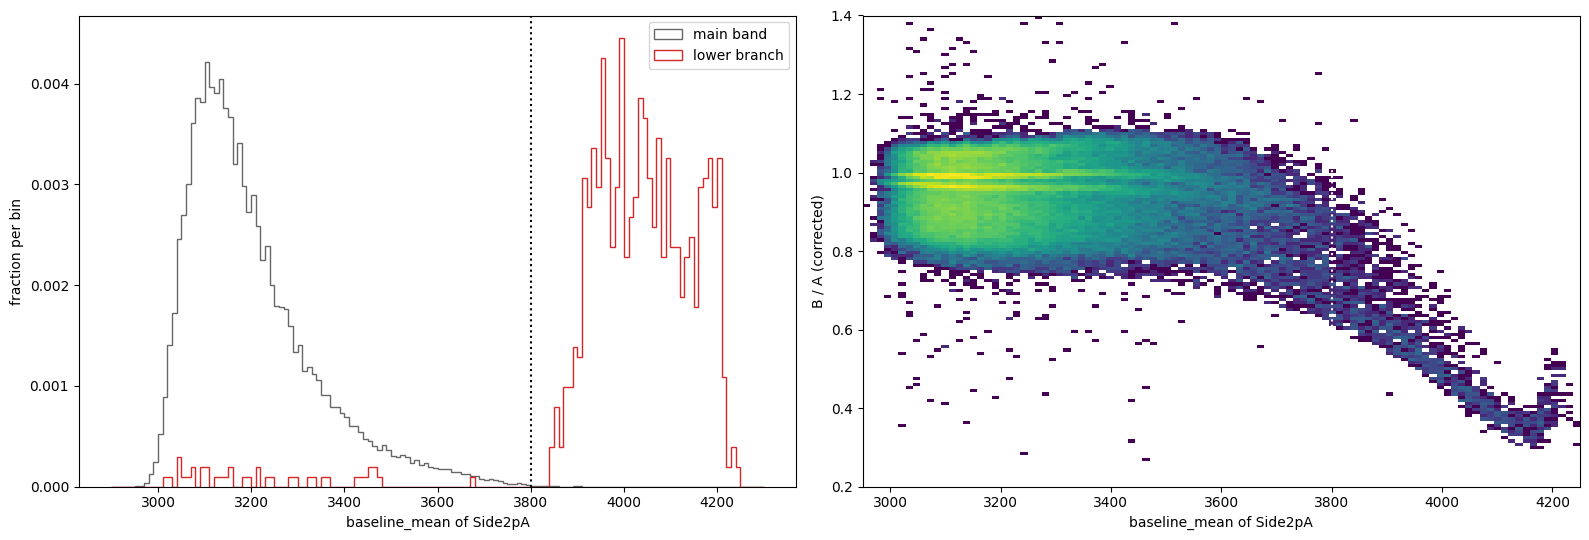

In [10]:
okc = A_c > 0.1; r_ = np.where(okc, B_c / np.maximum(A_c, 1e-9), np.nan)
low, up = okc & (r_ < 0.6), okc & (r_ > 1.12); main = okc & (r_ > 0.9) & (r_ < 1.05)
print(f"corrected B/A < 0.6: {low.sum():,} events; B/A > 1.12: {up.sum():,}; of {okc.sum():,} with A > 0.1")
for name, m in (("lower branch", low), ("main band", main), ("upper tail", up)):
    print(f"  {name:<13} baseline of A: median {np.median(bmean[P, 0][m]):6.0f}   10 to 90 %: {np.percentile(bmean[P, 0][m], 10):6.0f} .. {np.percentile(bmean[P, 0][m], 90):6.0f}")
fig, ax = plt.subplots(1, 2, figsize=(16, 5.5))
bb = np.linspace(2900, 4300, 141)
ax[0].hist(bmean[P, 0][main], bins=bb, histtype="step", density=True, color="0.4", label="main band"); ax[0].hist(bmean[P, 0][low], bins=bb, histtype="step", density=True, color="C3", label="lower branch")
ax[0].axvline(3800, color="k", ls=":"); ax[0].set_xlabel("baseline_mean of Side2pA"); ax[0].set_ylabel("fraction per bin"); ax[0].legend()
ax[1].hist2d(bmean[P, 0][okc], r_[okc], bins=[100, 150], range=[(2950, 4250), (0.2, 1.4)], norm=colors.LogNorm(), cmap="viridis", cmin=1)
ax[1].axvline(3800, color="w", ls=":"); ax[1].set_xlabel("baseline_mean of Side2pA"); ax[1].set_ylabel("B / A (corrected)")
fig.tight_layout()
plt.show()

## 6. What the pulses of the two branches are

Raw traces (before the line subtraction) of four events of each, channels A and B, with the straight line fitted to the tail (samples 2375 to 4095) in red and the integrated window (samples 400 to 1500) in orange. The traces are read from the dumps in `~/idx` (series `07221112_0943` only, a few events picked at random; the movies of 30 and 25 events are in `figures/lower-branch-corrected-AB-events.gif` and `figures/upper-branch-corrected-AB-events.gif`).

* **Lower branch:** the baseline is 3900 to 4200 counts (3200 for a normal event), the step at the trigger is small and the pulse decays so slowly that it has not returned to the baseline at the fit region, so the straight line cuts into it.
* **Upper tail:** a second, larger pulse lies in the fit region (or the trigger pulse is the small one and the large one follows); the line is tilted steeply and the window integral measures the ramp.

C:\Users\villanoa\AppData\Local\Temp\ipykernel_30412\2898942440.py:9: UserWarning: sensor_channels is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and channels 0 to 3 = board inputs pA to pD is assumed; not yet confirmed against the run's ODB
  SENSORS = {c_.name: (c_.detector, c_.channel) for c_ in pch.sensor_channels()}


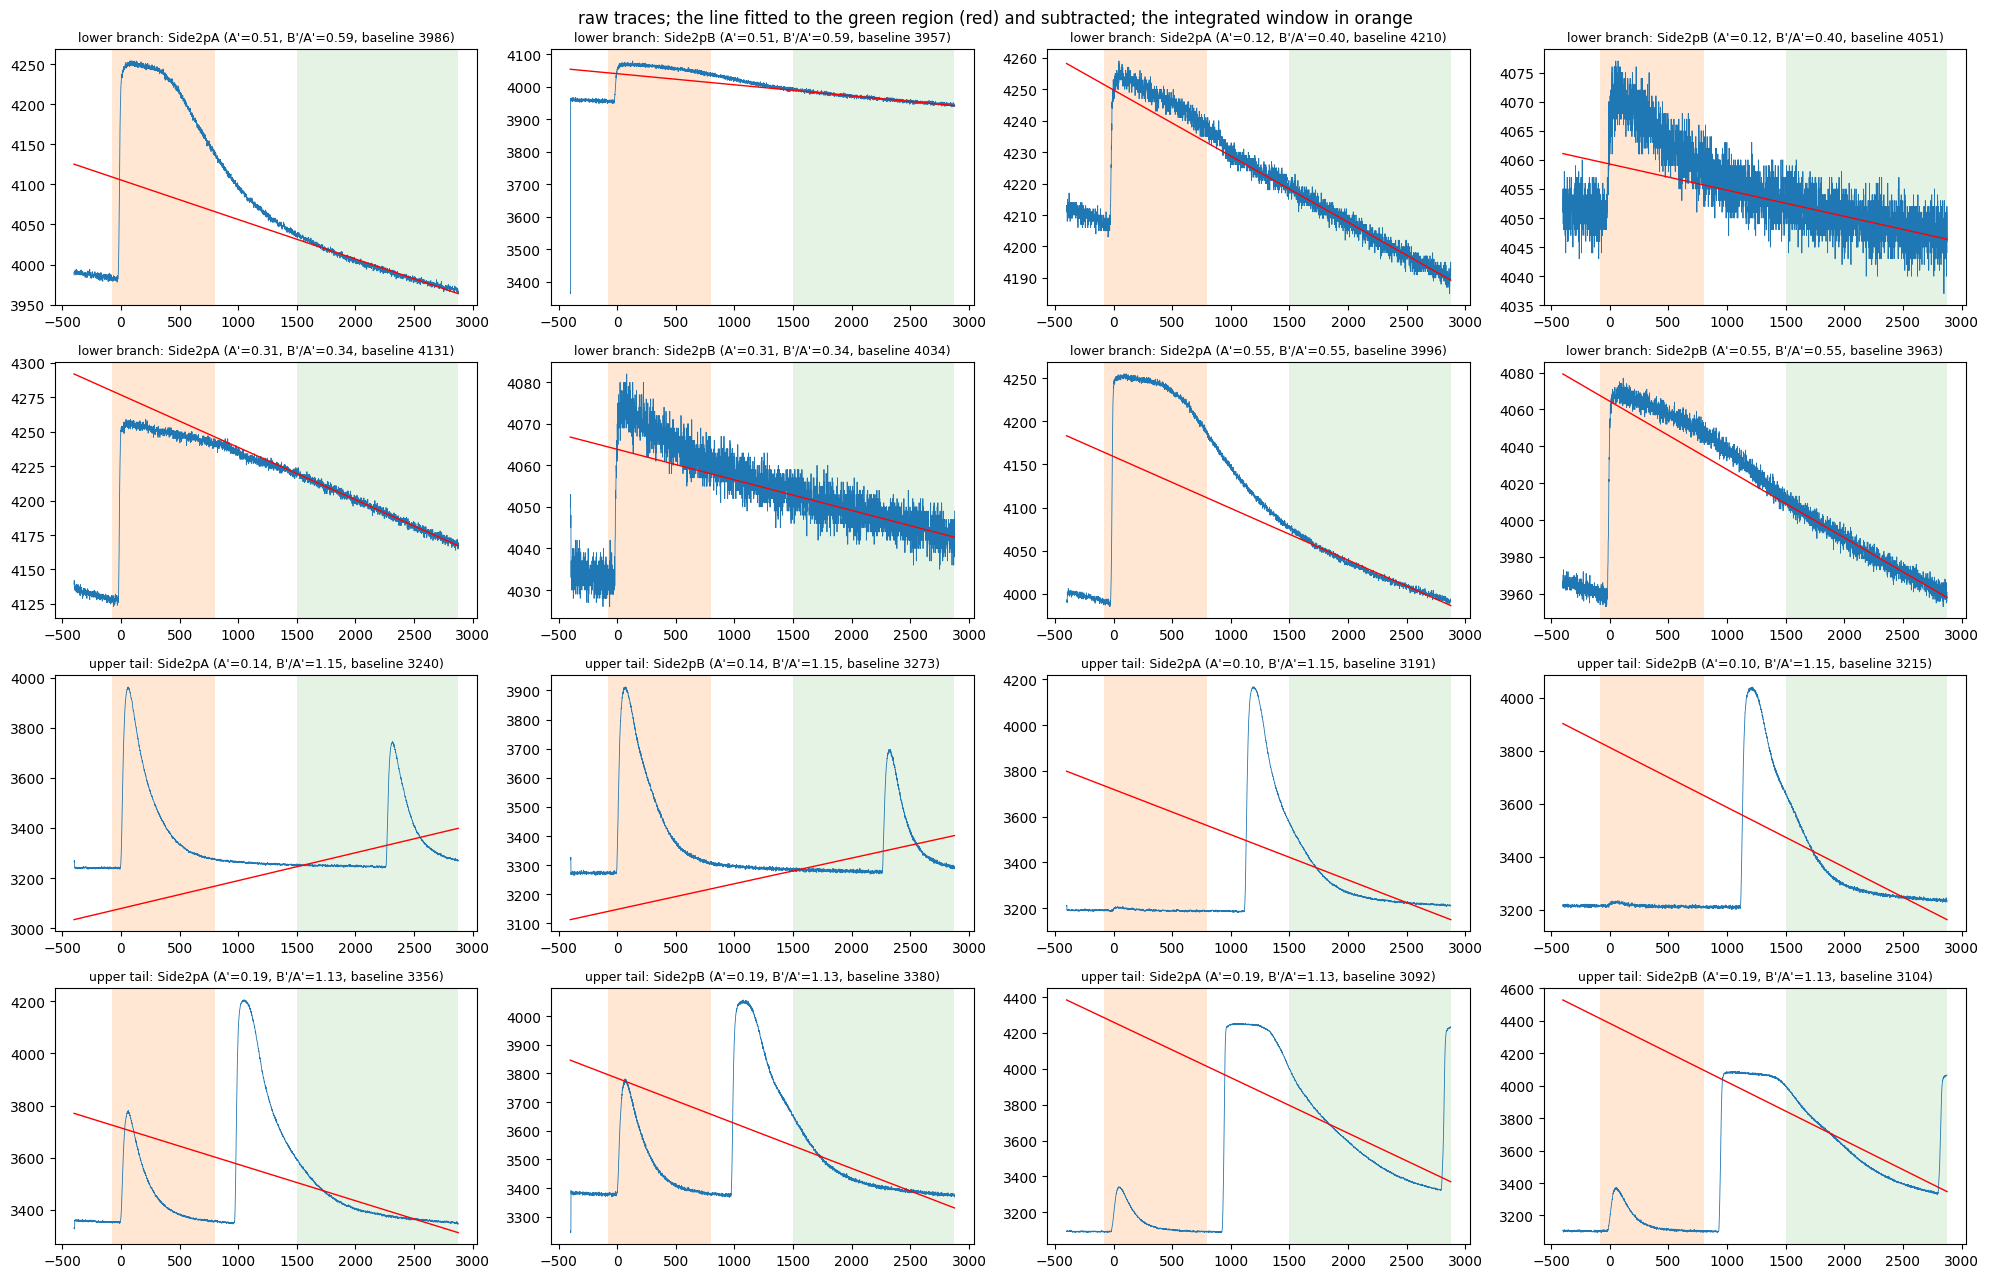

In [11]:
from goldpan.adapters import idx
from goldpan.config import PulseConfig
import goldpan.channels as pch

dump_lab = np.concatenate([np.asarray(pq.read_table(f, columns=["dump"])["dump"].to_pylist()) for f in files(OUT_WIN)])
event_no = np.concatenate([np.asarray(pq.read_table(f, columns=["event"])["event"].to_numpy(zero_copy_only=False)) for f in files(OUT_WIN)])
SER = "07221112_0943"
cfg = PulseConfig(pretrigger_samples=PRE, glitch_samples=10, sample_period_s=0.8e-6)
SENSORS = {c_.name: (c_.detector, c_.channel) for c_ in pch.sensor_channels()}
rng = np.random.default_rng(11)
m943 = series[P] == SER
pick = np.concatenate([rng.choice(np.flatnonzero(low & m943), 4, replace=False), rng.choice(np.flatnonzero(up & m943), 4, replace=False)])
kind = ["lower branch"] * 4 + ["upper tail"] * 4
raw = np.full((len(pick), 2, 4096), np.nan)
groups = {}
for n, loc in enumerate(pick):
    groups.setdefault(dump_lab[P[loc]], []).append((n, int(event_no[P[loc]])))
for d, items in sorted(groups.items()):
    ev = idx.read(Path.home() / "idx" / f"{SER}_{d}", detector_name="NAI-S2", channels=SENSORS, config=cfg)
    row = {int(e_): j for j, e_ in enumerate(np.asarray(ev.quantities["event"]))}
    seg = {nm_: s_ for (nm_, s_) in ev.traces}
    for n, e_ in items:
        for c_, k_ in enumerate("AB"):
            raw[n, c_] = np.asarray(ev.traces[(f"Side2p{k_}", seg[f"Side2p{k_}"])], dtype=float)[row[e_]]
FIT, WIN = (2375, 4096), (400, 1500)
t_us = (np.arange(4096) - 500) * 0.8; s_fit = np.arange(*FIT)
fig, axes = plt.subplots(4, 4, figsize=(20, 13))
for j in range(len(pick)):
    for c_ in (0, 1):
        ax = axes[j // 2, (j % 2) * 2 + c_]; tr = raw[j, c_]; fit = np.polyfit(s_fit, tr[s_fit], 1)
        ax.plot(t_us, tr, "C0", lw=0.6); ax.plot(t_us, np.polyval(fit, np.arange(4096)), "r", lw=1)
        ax.axvspan(t_us[FIT[0]], t_us[-1], color="C2", alpha=0.12, lw=0); ax.axvspan(t_us[WIN[0]], t_us[WIN[1]], color="C1", alpha=0.18, lw=0)
        loc = pick[j]; ax.set_title(f"{kind[j]}: Side2p{'AB'[c_]} (A'={A_c[loc]:.2f}, B'/A'={r_[loc]:.2f}, baseline {bmean[P[loc], c_]:.0f})", fontsize=9)
fig.suptitle("raw traces; the line fitted to the green region (red) and subtracted; the integrated window in orange", fontsize=12)
fig.tight_layout()
plt.show()

## 7. Cutting the high baselines, and A + B again

The events with the baseline of A or of B above 3800 are cut and the correction is refitted on the rest. The width and significance are compared, with a finer grid for the fit than `gfit` (60 x 60 steps in position and width), since `gfit`'s steps are about as large as the change. The B/A cuts (only for events with A above 0.08) are shown for comparison: removing the lower branch by its ratio does not change the peaks either.

baseline of A and B below 3800: kept 127,533 of 129,539 (98.5%)


A + B, all events                  59.5 keV: sigma/mu 0.0356  dchi2  14760 | 26.3 keV: sigma/mu 0.0262  dchi2   1767 | 22 keV: sigma/mu 0.0305  dchi2   1050


A + B, baseline < 3800 (refitted)  59.5 keV: sigma/mu 0.0344  dchi2  14718 | 26.3 keV: sigma/mu 0.0262  dchi2   1920 | 22 keV: sigma/mu 0.0299  dchi2   1092


A + B, B/A > 0.6 (1,053 cut)       59.5 keV: sigma/mu 0.0356  dchi2  14859 | 26.3 keV: sigma/mu 0.0262  dchi2   1796 | 22 keV: sigma/mu 0.0312  dchi2   1071


A + B, B/A > 0.75 (2,253 cut)      59.5 keV: sigma/mu 0.0356  dchi2  14884 | 26.3 keV: sigma/mu 0.0262  dchi2   1799 | 22 keV: sigma/mu 0.0305  dchi2   1074


A + B, B/A > 0.85 (15,600 cut)     59.5 keV: sigma/mu 0.0356  dchi2  14950 | 26.3 keV: sigma/mu 0.0262  dchi2   1802 | 22 keV: sigma/mu 0.0312  dchi2   1071


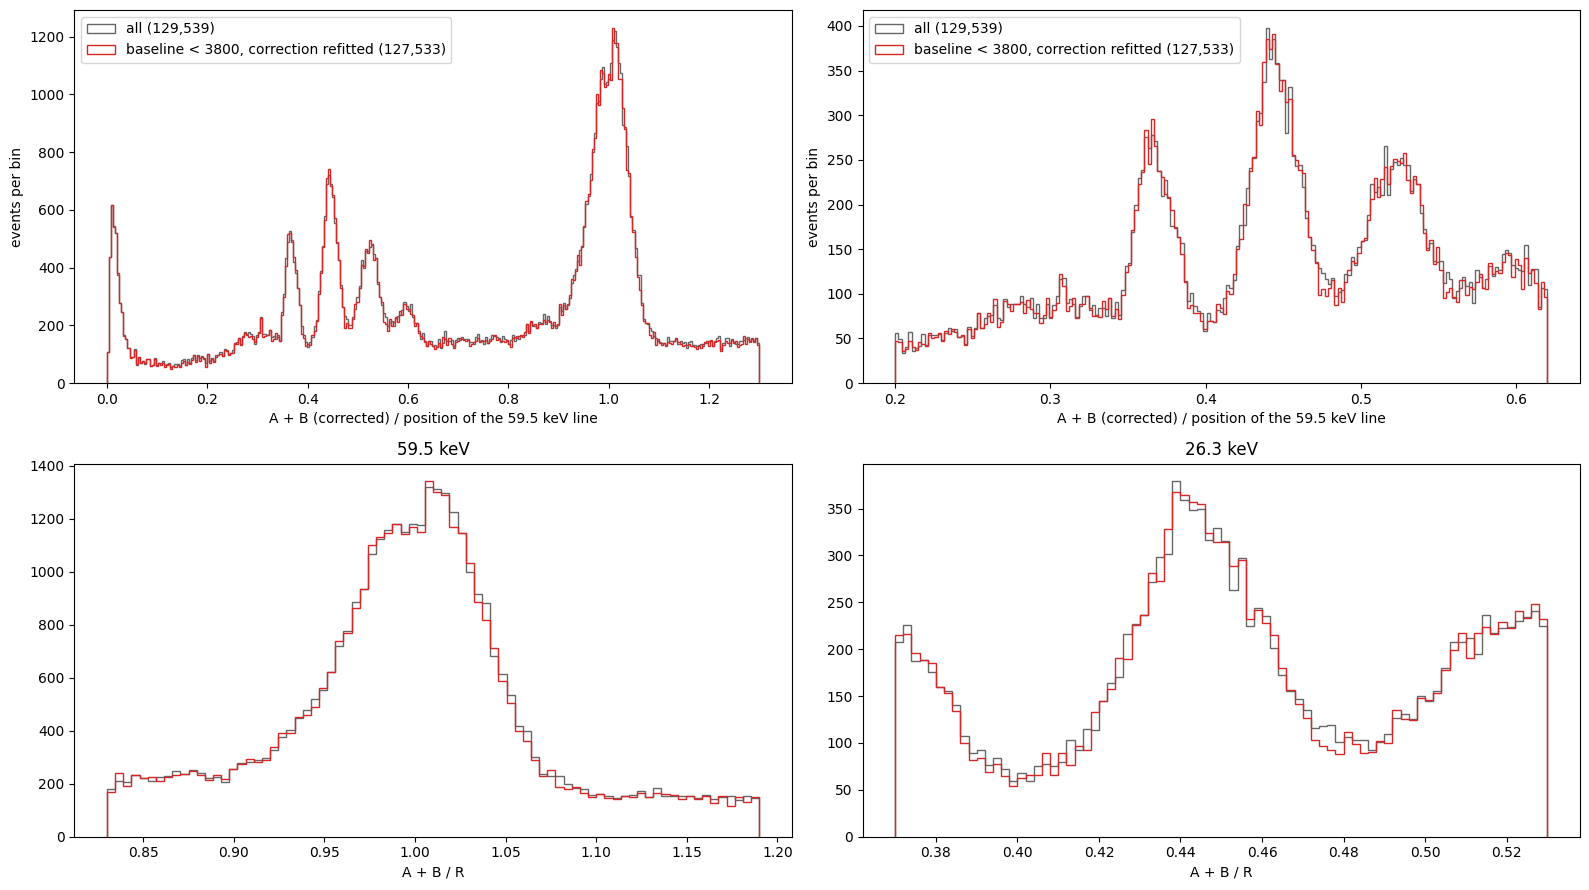

In [12]:
def fine(v, lo, hi, nb=80):
    e = np.linspace(lo, hi, nb + 1); c = 0.5 * (e[1:] + e[:-1]); h, _ = np.histogram(v, bins=e); w = 1 / np.sqrt(np.maximum(h, 1)); mid = 0.5 * (lo + hi)
    M0 = np.column_stack([np.ones_like(c), c - mid]); k0 = np.linalg.lstsq(M0 * w[:, None], h * w, rcond=None)[0]; chi0 = (((M0 @ k0 - h) * w) ** 2).sum()
    best = (1e18, 0, 0)
    for mu in np.linspace(lo + 0.25 * (hi - lo), hi - 0.25 * (hi - lo), 61):
        for sg in np.linspace(0.02 * (hi - lo), 0.2 * (hi - lo), 61):
            M = np.column_stack([np.exp(-0.5 * ((c - mu) / sg) ** 2), M0]); k = np.linalg.lstsq(M * w[:, None], h * w, rcond=None)[0]
            if k[0] <= 0:
                continue
            chi = (((M @ k - h) * w) ** 2).sum()
            if chi < best[0]:
                best = (chi, mu, sg)
    return chi0 - best[0], best[1], best[2]

def peaks(v, R, name):
    out = []
    for lab, lo, hi, nb_ in (("59.5", 0.80, 1.20, 80), ("26.3", 0.38, 0.52, 70), ("22", 0.33, 0.41, 60)):
        d, mu, sg = fine(v, lo * R, hi * R, nb_); out.append(f"{lab} keV: sigma/mu {sg / mu:.4f}  dchi2 {d:6.0f}")
    print(f"{name:<34}", " | ".join(out))

cutb = (bmean[P, 0] < 3800) & (bmean[P, 1] < 3800)
print(f"baseline of A and B below 3800: kept {cutb.sum():,} of {len(cutb):,} ({cutb.mean():.1%})")
Ak, RAk, *_ = correct(wint[P, 0][cutb], bmean[P, 0][cutb], INIT[0]); Bk, RBk, *_ = correct(wint[P, 1][cutb], bmean[P, 1][cutb], INIT[1])
S_all, R_all, S_cut, R_cut = A_c + B_c, RA + RB, Ak + Bk, RAk + RBk
peaks(S_all, R_all, "A + B, all events")
peaks(S_cut, R_cut, "A + B, baseline < 3800 (refitted)")
for thr in (0.6, 0.75, 0.85):
    k2 = ~((A_c > 0.08) & (np.where(A_c > 0.08, B_c / np.maximum(A_c, 1e-9), 1) < thr))
    peaks((A_c + B_c)[k2], R_all, f"A + B, B/A > {thr} ({(~k2).sum():,} cut)")
fig, axes = plt.subplots(2, 2, figsize=(16, 9))
for ax, (lo, hi, nbn) in zip(axes[0], ((0, 1.3, 320), (0.2, 0.62, 200))):
    e = np.linspace(lo, hi, nbn)
    ax.hist(S_all / R_all, bins=e, histtype="step", color="0.4", label=f"all ({len(S_all):,})")
    ax.hist(S_cut / R_cut, bins=e, histtype="step", color="C3", label=f"baseline < 3800, correction refitted ({cutb.sum():,})")
    ax.set_xlabel("A + B (corrected) / position of the 59.5 keV line"); ax.set_ylabel("events per bin"); ax.legend()
for ax, (lab, lo, hi) in zip(axes[1], (("59.5 keV", 0.83, 1.19), ("26.3 keV", 0.37, 0.53))):
    e = np.linspace(lo, hi, 81); ax.hist(S_all / R_all, bins=e, histtype="step", color="0.4"); ax.hist(S_cut / R_cut, bins=e, histtype="step", color="C3"); ax.set_title(lab); ax.set_xlabel("A + B / R")
fig.tight_layout()
plt.show()